In [24]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression # 가장 많이 사용
from sklearn.neighbors import KNeighborsRegressor 
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동완성
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler# 정규화 클래스
from sklearn.linear_model import Ridge # 릿지규제
from sklearn.linear_model import Lasso # 라쏘규제
from sklearn.model_selection import train_test_split
import numpy as np
from io import StringIO

In [4]:
# 무게 데이터
perch_weight = [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]

In [5]:
df = pd.read_csv('data/perch_full.csv')
df.head(2)

,length,height,width
0,8.4,2.11,1.41
1,13.7,3.53,2.00


In [8]:
# 데이터 전처리
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(df,perch_weight,random_state=42)
train_data.head(2)

,length,height,width
8,19.6,5.14,3.04
17,22.0,5.88,3.52


In [37]:
poly = PolynomialFeatures(degree=16,include_bias=False) # 기본값 1을 제외함
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)

In [40]:
len(poly.get_feature_names_out())

968

In [22]:
# 규제 정규화
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)


In [ ]:
# 규제의 강도를 높여서 확인
alpha_list = [0.001,0.01,0.1,1,10,100]
score = []
score2 = []
for a in alpha_list:
    lasso = Lasso(alpha=a) # default값으로 원래 1이 있음
    lasso.fit(train_scaled,train_label)
    s1 = lasso.score(train_scaled,train_label)
    s2 = lasso.score(test_scaled,test_label)
    score.append(s1)
    score2.append(s2)
score,score2

c:\pythin313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.082349e+03, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
c:\pythin313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.527587e+03, tolerance: 5.183e+02
  model = cd_fast.enet_coordinate_descent(
c:\pythin313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.346637e+03, tolerance: 5.183e+02
  model = cd_f

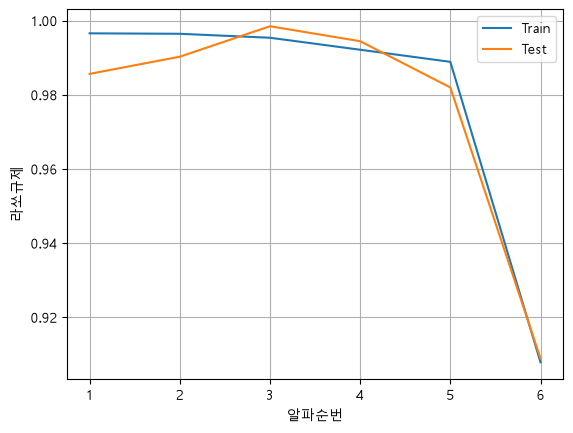

In [32]:
# 규제의 강도를 높여서 확인
alpha_list = [0.001,0.01,0.1,1,10,100]
score = []
score2 = []
for a in alpha_list:
    lasso = Lasso(alpha=a) # default값으로 원래 1이 있음
    lasso.fit(train_scaled,train_label)
    s1 = lasso.score(train_scaled,train_label)
    s2 = lasso.score(test_scaled,test_label)
    score.append(s1)
    score2.append(s2)
score,score2

no_list = list(range(1,7))
plt.plot(no_list,score)
plt.plot(no_list,score2)
plt.legend(('Train','Test'))
plt.grid()
plt.xlabel('알파순번')
plt.ylabel('라쏘규제')
plt.show()

In [33]:
# 데이터 학습
lr = LinearRegression()
lr.fit(train_poly,train_label)

# 데이터 예측
predict = lr.predict(test_poly)

# 졍확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
score,score2

(0.9453093526621708, -0.1355617036882999)

In [36]:
# 데이터 학습
lasso = Lasso(alpha=10)
lasso.fit(train_scaled,train_label)

# 데이터 예측
predict = lasso.predict(test_poly)

# 졍확도
scor = lasso.score(train_scaled,train_label)
scor2 = lasso.score(test_scaled,test_label)
scor,scor2

(0.9888733727494778, 0.9819696830089489)